In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from pathlib import Path

INTERP = Path('/n/holylfs06/LABS/kempner_project_b/Lab/dendritic/adivm/dendritic-modeling/outputs/interpretability_results')
FIG_DIR = Path('figures'); FIG_DIR.mkdir(exist_ok=True)

TAGS   = {'2x2': 'fc7_2x2_ne4096', '3x3x3': 'fc7_3x3x3_ne4096'}
COLORS = {'2x2': '#2a78d6', '3x3x3': '#1baf7a'}
N_E, N_CLASSES = 4096, 1000

def load(tag, name): return np.load(INTERP / tag / f'{name}.npy')

data = {}
for label, tag in TAGS.items():
    data[label] = {
        'W':     load(tag, 'fc8_weight_projection'),     # (N_E, 1000)
        'acts':  load(tag, 'val_activations'),           # (50000, N_E)
        'lbls':  load(tag, 'val_labels'),                # (50000,)
        'pcm':   load(tag, 'per_class_mean_act'),        # (N_E, 1000)
        'sel':   load(tag, 'selectivity_index'),         # (N_E,)
        'top_w': load(tag, 'top_classes_by_weight'),     # (N_E, 10)
        'top_a': load(tag, 'top_classes_by_activation'), # (N_E, 10)
        'base_acc':   load(tag, 'baseline_class_acc'),   # (1000,)
        'abl_delta':  load(tag, 'ablation_acc_delta'),   # (N_E, 1000)
    }
    print(f"{label}: loaded. sel mean={data[label]['sel'].mean():.4f}  max={data[label]['sel'].max():.4f}")

2x2: loaded. sel mean=0.0859  max=0.2891
3x3x3: loaded. sel mean=0.0789  max=0.2779


## Figure 2 — Class coverage histogram
How many neurons have each class as their top-1 fc8 weight target? Expected if uniform = 4096/1000 ≈ 4.1.

In [2]:
import json
# Load ImageNet class names if available
try:
    import torchvision
    ds = torchvision.datasets.ImageNet('/n/holylfs06/LABS/kempner_shared/Everyone/testbed/vision/imagenet_1k', split='val')
    idx_to_class = {v: k for k, v in ds.class_to_idx.items()}
    class_names = {i: ds.classes[i][0] if isinstance(ds.classes[i], (list,tuple)) else ds.classes[i] for i in range(1000)}
    has_names = True
except Exception as e:
    print(f"Class names unavailable: {e}")
    has_names = False
    class_names = {i: str(i) for i in range(1000)}


2x2 top-5 over-represented classes:
  1. pool table (736) — 24 neurons
  2. bobsled (450) — 22 neurons
  3. axolotl (29) — 21 neurons
  4. apiary (410) — 20 neurons
  5. space shuttle (812) — 20 neurons

3x3x3 top-5 over-represented classes:
  1. space shuttle (812) — 31 neurons
  2. sewing machine (786) — 24 neurons
  3. pool table (736) — 23 neurons
  4. pickelhaube (715) — 21 neurons
  5. axolotl (29) — 20 neurons


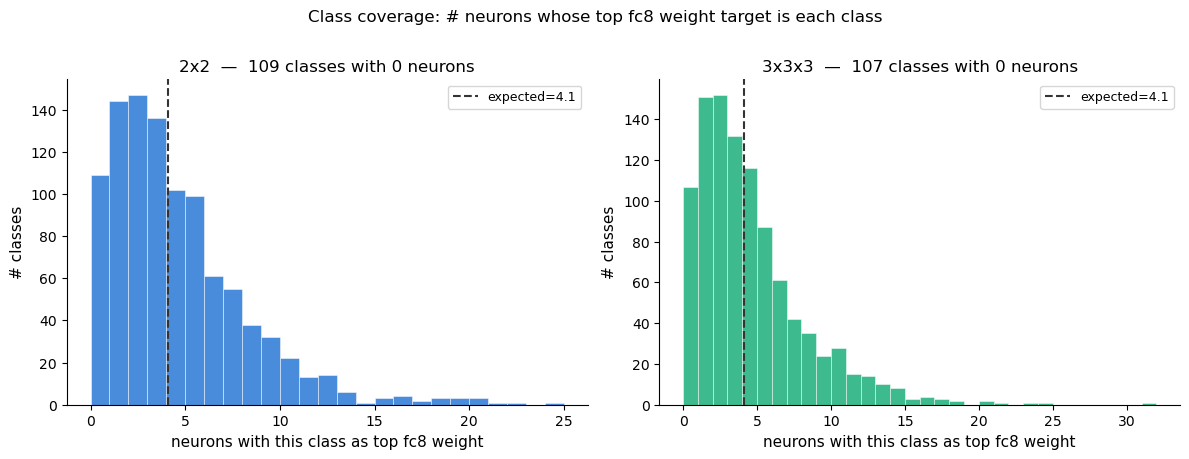

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
expected = N_E / N_CLASSES

for ax, (label, d) in zip(axes, data.items()):
    top1 = d['W'].argmax(axis=1)                        # (N_E,) — each neuron's top excitatory class
    counts = np.bincount(top1, minlength=N_CLASSES)     # (1000,)

    ax.hist(counts, bins=range(0, counts.max()+2), color=COLORS[label],
            edgecolor='white', lw=0.4, alpha=0.85)
    ax.axvline(expected, color='#333', lw=1.5, ls='--', label=f'expected={expected:.1f}')
    ax.set_xlabel('neurons with this class as top fc8 weight', fontsize=11)
    ax.set_ylabel('# classes', fontsize=11)
    ax.set_title(f'{label}  —  {(counts==0).sum()} classes with 0 neurons', fontsize=12)
    ax.legend(fontsize=9)
    ax.spines[['top','right']].set_visible(False)

    # Print top-5
    top5_idx = np.argsort(counts)[::-1][:5]
    print(f"\n{label} top-5 over-represented classes:")
    for rank, idx in enumerate(top5_idx, 1):
        print(f"  {rank}. {class_names[idx]} ({idx}) — {counts[idx]} neurons")

plt.suptitle('Class coverage: # neurons whose top fc8 weight target is each class', fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig2_class_coverage.pdf', bbox_inches='tight')
plt.show()

## Metric discussion: measuring class specialization

Three candidates:
1. **Lifetime sparseness S** (Vinje & Gallant 2000) — `selectivity_index.npy`. Already computed. Standard neuroscience metric. S≈1 = responds to 1 class; S≈0 = responds uniformly to all.
2. **Peak ratio** = max(mean_act_per_class) / mean(mean_act_per_class). Simple, interpretable.
3. **Ablation impact** = Σ|Δacc| across all classes when neuron is zeroed. Ground-truth: does this neuron *causally* carry class info?

Recommendation: use (1) as the primary axis (established, comparable to prior literature), show (3) as validation — if high-S neurons also have high ablation impact, the metric is meaningful.

In [ ]:
# Quick look at the selectivity distribution
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (label, d) in zip(axes, data.items()):
    ax.hist(d['sel'], bins=80, color=COLORS[label], edgecolor='none', alpha=0.85)
    ax.axvline(d['sel'].mean(), color='#333', lw=1.2, ls='--',
               label=f"mean={d['sel'].mean():.3f}")
    ax.set_xlabel('lifetime sparseness S', fontsize=11)
    ax.set_ylabel('# neurons', fontsize=11)
    ax.set_title(f'{label}', fontsize=12)
    ax.legend(fontsize=9)
    ax.spines[['top','right']].set_visible(False)
plt.suptitle('Lifetime sparseness distribution (S=1: single class, S=0: uniform)', fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig_selectivity_dist.pdf', bbox_inches='tight')
plt.show()

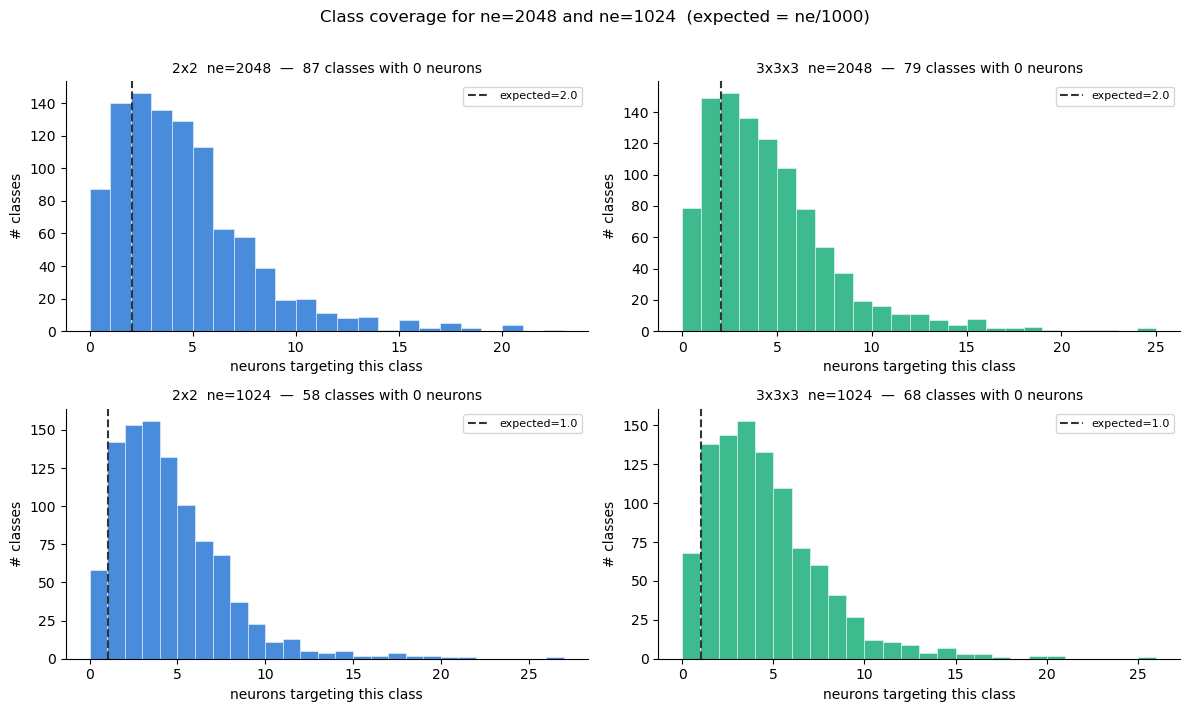

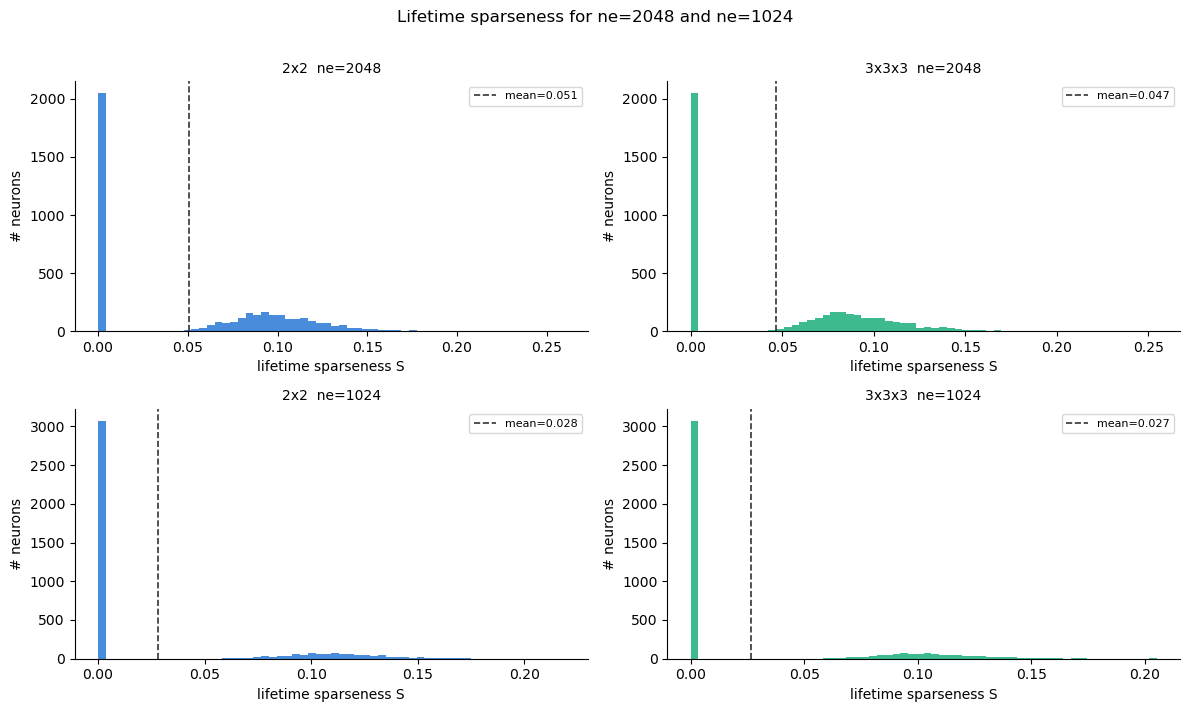

In [5]:
# Class coverage + lifetime sparseness for ne=2048 and ne=1024 (both morphologies)
NE_SWEEP   = [2048, 1024]
MORPHS     = ['2x2', '3x3x3']
MORPH_COLS = {'2x2': '#2a78d6', '3x3x3': '#1baf7a'}

fig_A, axes_A = plt.subplots(len(NE_SWEEP), len(MORPHS), figsize=(12, 7), sharey=False)
fig_B, axes_B = plt.subplots(len(NE_SWEEP), len(MORPHS), figsize=(12, 7), sharey=False)

for row, ne in enumerate(NE_SWEEP):
    for col, morph in enumerate(MORPHS):
        tag   = f'fc7_{morph}_ne{ne}'
        color = MORPH_COLS[morph]

        W   = np.load(INTERP / tag / 'fc8_weight_projection.npy')   # (ne, 1000)
        sel = np.load(INTERP / tag / 'selectivity_index.npy')        # (ne,)

        # --- Class coverage ---
        ax = axes_A[row, col]
        top1     = W.argmax(axis=1)
        counts   = np.bincount(top1, minlength=1000)
        expected = ne / 1000
        ax.hist(counts, bins=range(0, counts.max()+2), color=color,
                edgecolor='white', lw=0.4, alpha=0.85)
        ax.axvline(expected, color='#333', lw=1.5, ls='--', label=f'expected={expected:.1f}')
        ax.set_xlabel('neurons targeting this class', fontsize=10)
        ax.set_ylabel('# classes', fontsize=10)
        ax.set_title(f'{morph}  ne={ne}  —  {(counts==0).sum()} classes with 0 neurons', fontsize=10)
        ax.legend(fontsize=8)
        ax.spines[['top','right']].set_visible(False)

        # --- Lifetime sparseness ---
        ax = axes_B[row, col]
        ax.hist(sel, bins=60, color=color, edgecolor='none', alpha=0.85)
        ax.axvline(sel.mean(), color='#333', lw=1.2, ls='--', label=f'mean={sel.mean():.3f}')
        ax.set_xlabel('lifetime sparseness S', fontsize=10)
        ax.set_ylabel('# neurons', fontsize=10)
        ax.set_title(f'{morph}  ne={ne}', fontsize=10)
        ax.legend(fontsize=8)
        ax.spines[['top','right']].set_visible(False)

fig_A.suptitle('Class coverage for ne=2048 and ne=1024  (expected = ne/1000)', fontsize=12, y=1.01)
fig_A.tight_layout()
fig_A.savefig(FIG_DIR / 'fig_coverage_ne2048_1024.pdf', bbox_inches='tight')

fig_B.suptitle('Lifetime sparseness for ne=2048 and ne=1024', fontsize=12, y=1.01)
fig_B.tight_layout()
fig_B.savefig(FIG_DIR / 'fig_sparseness_ne2048_1024.pdf', bbox_inches='tight')

plt.show()

## Figure 4 — Raster map: per-class mean activation (neurons × classes)
Neurons sorted by their top activation class. Diagonal = class-specialized.

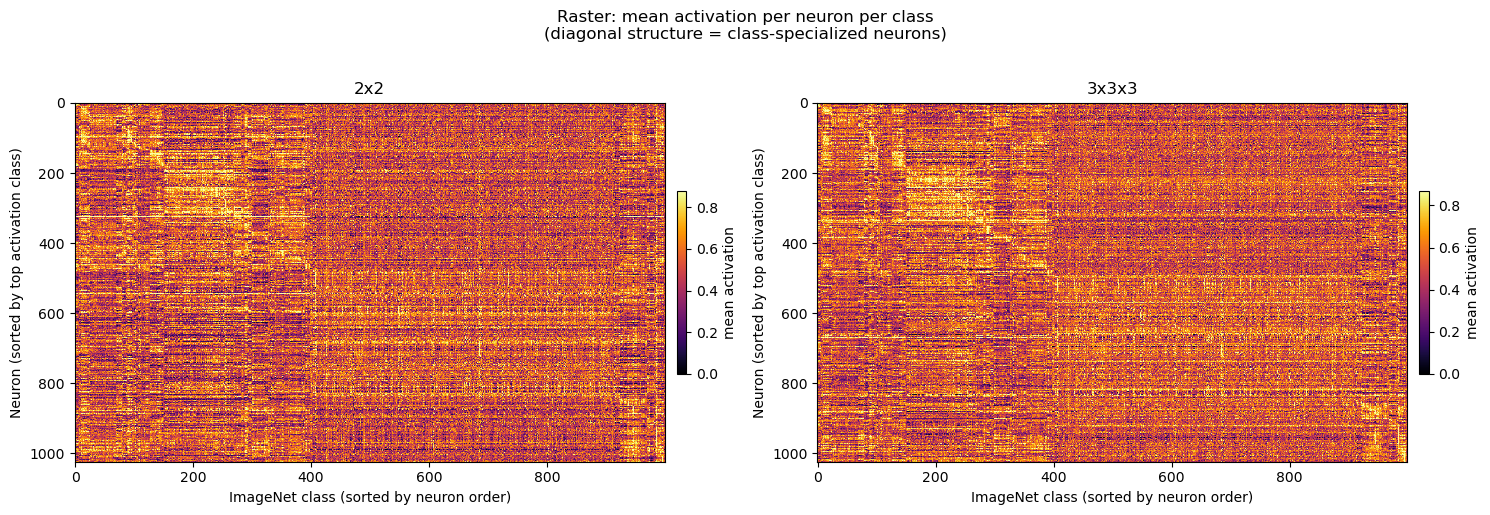

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, (label, d) in zip(axes, data.items()):
    pcm = d['pcm']                                 # (N_E, 1000)
    order = np.argsort(pcm.argmax(axis=1))         # sort neurons by their top class
    pcm_sorted = pcm[order][::4]                   # subsample every 4th neuron for display

    vmax = np.percentile(pcm_sorted, 99)
    im = ax.imshow(pcm_sorted, aspect='auto', cmap='inferno',
                   vmin=0, vmax=vmax, interpolation='nearest')
    ax.set_xlabel('ImageNet class (sorted by neuron order)', fontsize=10)
    ax.set_ylabel('Neuron (sorted by top activation class)', fontsize=10)
    ax.set_title(f'{label}', fontsize=12)
    plt.colorbar(im, ax=ax, fraction=0.015, pad=0.02, label='mean activation')

plt.suptitle('Raster: mean activation per neuron per class\n(diagonal structure = class-specialized neurons)',
             fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig4_raster_map.pdf', bbox_inches='tight')
plt.show()

2x2: loaded. sel mean=0.0859  max=0.2891
3x3x3: loaded. sel mean=0.0789  max=0.2779
2x2: preferred class is an ANIMAL (<398) for 46.4% of units (chance 39.8%) | a DOG (151-268) for 13.4% (chance 11.8%)
3x3x3: preferred class is an ANIMAL (<398) for 48.0% of units (chance 39.8%) | a DOG (151-268) for 13.7% (chance 11.8%)


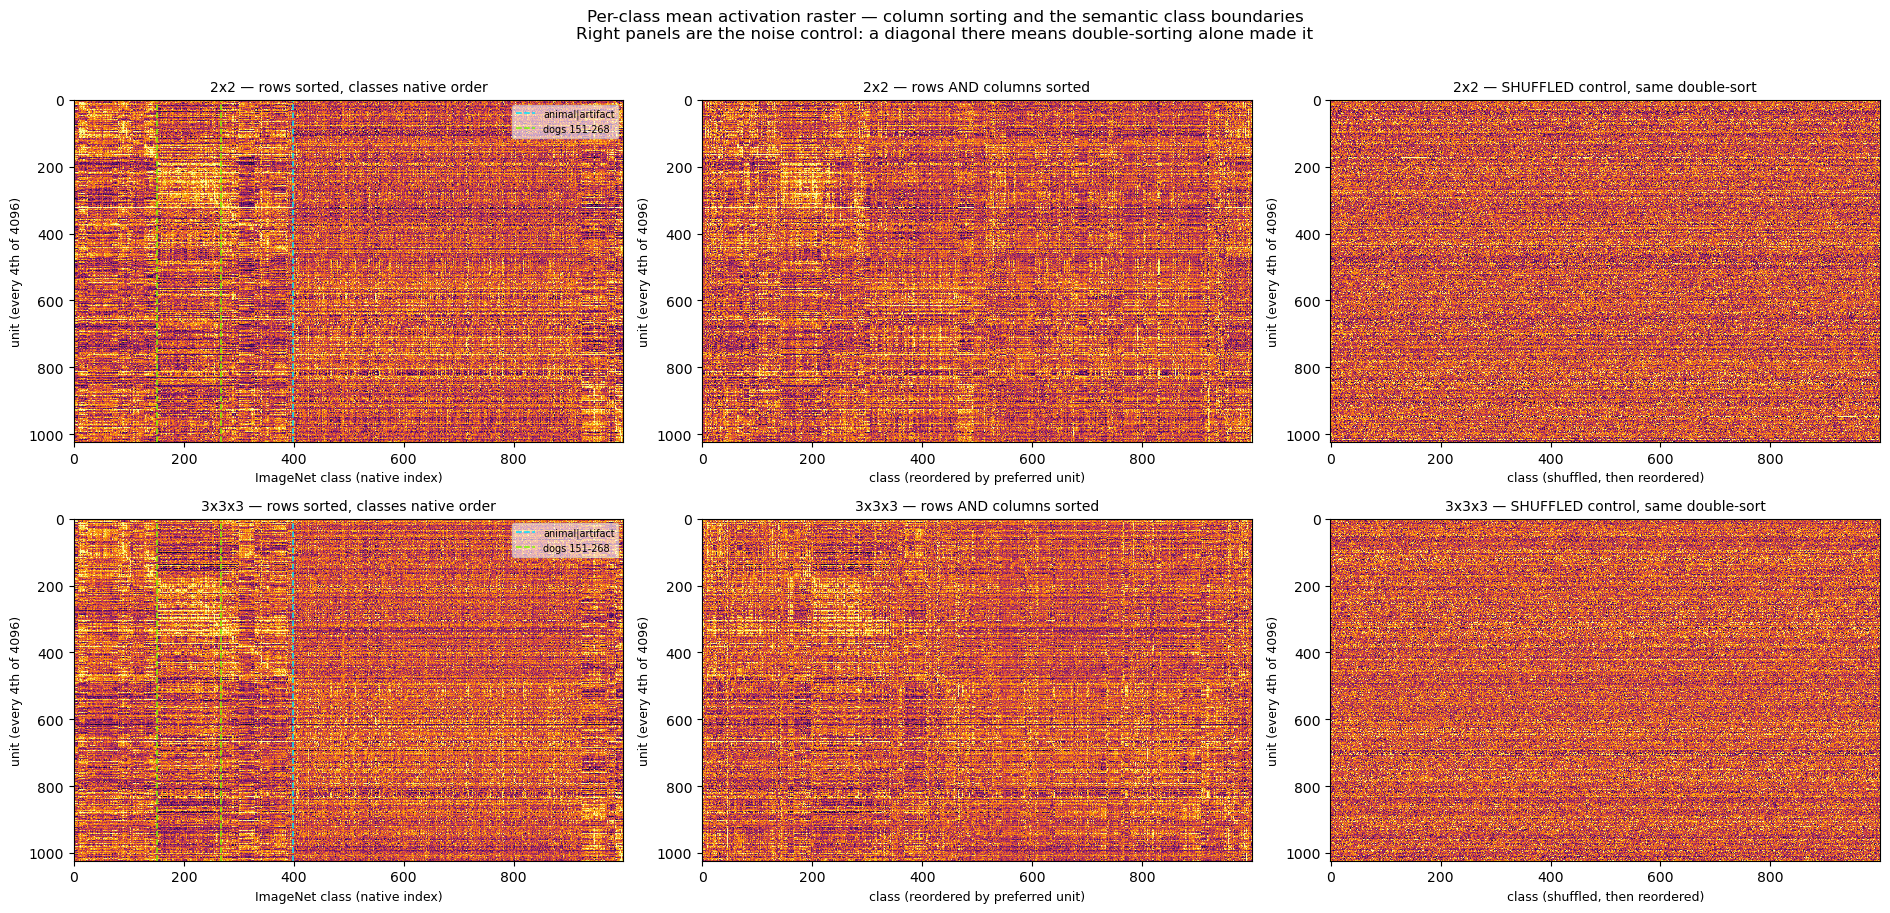

In [1]:
# ── Raster with BOTH axes sorted, plus the semantic class boundaries ─────────
# NEW CELL. The original raster cell above is unchanged.
#
# Bernardo asked (a) can we sort the columns too, and (b) is anything special about
# the class cutoffs. Both addressed here.
#
# (b) YES, the cutoffs are real. ImageNet class index = position in sorted-WordNet-ID
#     order (what ImageFolder uses), and WordNet IDs are taxonomically grouped:
#         0-397    animals    (397 = puffer, the last one)
#         398-999  artifacts  (398 = abacus, the first one)
#         151-268  dogs       (Chihuahua ... Mexican hairless, 118 breeds)
#     The vertical discontinuity at x~400 in the original raster is exactly the
#     animal -> artifact boundary. CAVEAT: within the artifact block the ordering is
#     essentially ALPHABETICAL (abacus, abaya, academic gown, accordion), so
#     horizontal structure at x>400 is semantically arbitrary; only x<400 is taxonomic.
#
# (a) Columns sorted by which unit responds most. IMPORTANT: sorting both axes by each
#     other's argmax manufactures a diagonal even from pure noise, so the third panel
#     is a SHUFFLED CONTROL -- the same double-sort applied to data whose class
#     structure has been destroyed. Compare against it before believing any diagonal.

ANIMAL_END, DOG_START, DOG_END = 398, 151, 268
rng = np.random.default_rng(0)

fig, axes = plt.subplots(2, 3, figsize=(19, 9))

for row, (label, d) in enumerate(data.items()):
    pcm = d['pcm']                                   # (N_E, 1000)
    sub = max(1, pcm.shape[0] // 1024)
    vmax = np.percentile(pcm, 99)                    # shared scale across the row

    # panel 1: rows sorted, columns native, semantic boundaries marked
    r_order = np.argsort(pcm.argmax(axis=1))
    ax = axes[row, 0]
    ax.imshow(pcm[r_order][::sub], aspect='auto', cmap='inferno',
              vmin=0, vmax=vmax, interpolation='nearest')
    ax.axvline(ANIMAL_END, color='#00e5ff', lw=1.1, ls='--', label='animal|artifact')
    ax.axvline(DOG_START, color='#7CFC00', lw=1.1, ls='--', label='dogs 151-268')
    ax.axvline(DOG_END,   color='#7CFC00', lw=1.1, ls='--')
    ax.set_title(f'{label} — rows sorted, classes native order', fontsize=10)
    ax.set_xlabel('ImageNet class (native index)', fontsize=9)
    ax.legend(fontsize=7, loc='upper right', framealpha=0.6)

    # panel 2: BOTH axes sorted
    c_order = np.argsort(pcm[r_order].argmax(axis=0))
    ax = axes[row, 1]
    ax.imshow(pcm[np.ix_(r_order, c_order)][::sub], aspect='auto', cmap='inferno',
              vmin=0, vmax=vmax, interpolation='nearest')
    ax.set_title(f'{label} — rows AND columns sorted', fontsize=10)
    ax.set_xlabel('class (reordered by preferred unit)', fontsize=9)

    # panel 3: shuffled control, identical double-sort
    sh = rng.permuted(pcm, axis=1)
    r2 = np.argsort(sh.argmax(axis=1))
    c2 = np.argsort(sh[r2].argmax(axis=0))
    ax = axes[row, 2]
    ax.imshow(sh[np.ix_(r2, c2)][::sub], aspect='auto', cmap='inferno',
              vmin=0, vmax=vmax, interpolation='nearest')
    ax.set_title(f'{label} — SHUFFLED control, same double-sort', fontsize=10)
    ax.set_xlabel('class (shuffled, then reordered)', fontsize=9)

    for c in range(3):
        axes[row, c].set_ylabel(f'unit (every {sub}th of {pcm.shape[0]})', fontsize=9)

    pref = pcm.argmax(axis=1)
    fa = (pref < ANIMAL_END).mean() * 100
    fd = ((pref >= DOG_START) & (pref <= DOG_END)).mean() * 100
    print(f'{label}: preferred class is an ANIMAL (<398) for {fa:.1f}% of units '
          f'(chance {ANIMAL_END/10:.1f}%) | a DOG (151-268) for {fd:.1f}% '
          f'(chance {(DOG_END-DOG_START+1)/10:.1f}%)')

plt.suptitle('Per-class mean activation raster — column sorting and the semantic class boundaries\n'
             'Right panels are the noise control: a diagonal there means double-sorting alone made it',
             fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig_raster_biclustered_with_controls.pdf', bbox_inches='tight')
plt.show()

## Class accuracy vs neuron specialization
For each class: mean selectivity index of neurons that prefer it (top fc8 weight). Does having more specialized neurons = better class accuracy?

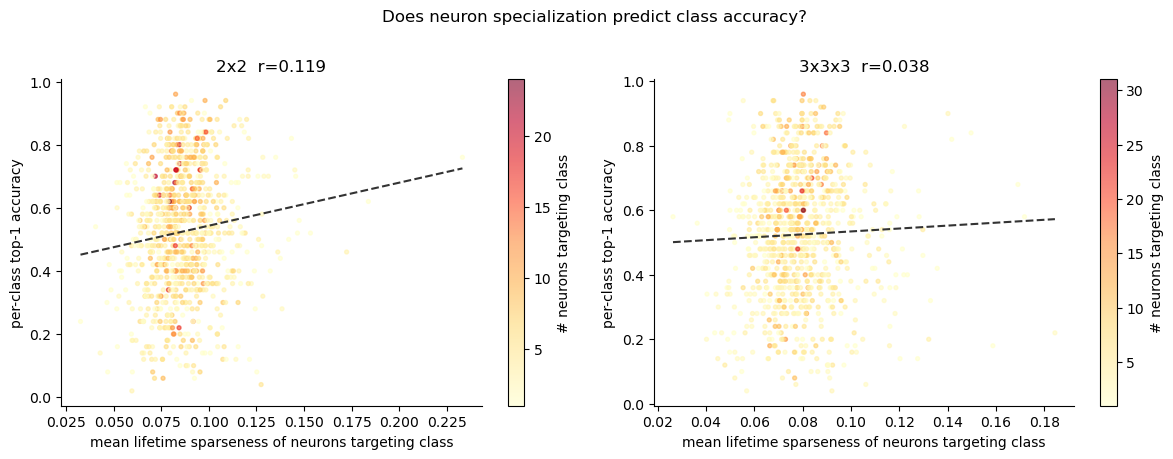

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, (label, d) in zip(axes, data.items()):
    top1 = d['W'].argmax(axis=1)           # each neuron's top class by weight
    sel  = d['sel']                        # (N_E,)
    base = d['base_acc']                   # (1000,)

    # For each class: mean selectivity of neurons that target it
    class_mean_sel = np.zeros(N_CLASSES)
    class_n_neurons = np.bincount(top1, minlength=N_CLASSES)
    for c in range(N_CLASSES):
        mask = top1 == c
        class_mean_sel[c] = sel[mask].mean() if mask.sum() > 0 else np.nan

    # Scatter: class accuracy vs mean selectivity of its neurons
    valid = ~np.isnan(class_mean_sel)
    sc = ax.scatter(class_mean_sel[valid], base[valid],
                    c=class_n_neurons[valid], cmap='YlOrRd',
                    s=8, alpha=0.6, rasterized=True)
    plt.colorbar(sc, ax=ax, label='# neurons targeting class')

    # Trend line
    z = np.polyfit(class_mean_sel[valid], base[valid], 1)
    p = np.poly1d(z)
    xr = np.linspace(class_mean_sel[valid].min(), class_mean_sel[valid].max(), 100)
    ax.plot(xr, p(xr), color='#333', lw=1.5, ls='--')
    r = np.corrcoef(class_mean_sel[valid], base[valid])[0,1]

    ax.set_xlabel('mean lifetime sparseness of neurons targeting class', fontsize=10)
    ax.set_ylabel('per-class top-1 accuracy', fontsize=10)
    ax.set_title(f'{label}  r={r:.3f}', fontsize=12)
    ax.spines[['top','right']].set_visible(False)

plt.suptitle('Does neuron specialization predict class accuracy?', fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig_acc_vs_selectivity.pdf', bbox_inches='tight')
plt.show()

## Ablation impact vs selectivity — 3 morphologies, dead-neuron filter

Bernardo's point: the negative correlation may be driven by dead neurons (S=0 AND impact≈0).
Here we compare **point** (no dendrites) vs **2x2** vs **3x3x3**, and show raw vs active-only.

In [ ]:
THREE_WAY = {
    'point': {'tag': 'fc7_point_ne4096', 'color': '#e07b39'},
    '2x2':   {'tag': 'fc7_2x2_ne4096',   'color': '#2a78d6'},
    '3x3x3': {'tag': 'fc7_3x3x3_ne4096', 'color': '#1baf7a'},
}

# Load data for all three morphologies
tw_data = {}
for label, info in THREE_WAY.items():
    tag = info['tag']
    tw_data[label] = {
        'pcm':       np.load(INTERP / tag / 'per_class_mean_act.npy'),   # (N_E, 1000)
        'sel':       np.load(INTERP / tag / 'selectivity_index.npy'),    # (N_E,)
        'abl_delta': np.load(INTERP / tag / 'ablation_acc_delta.npy'),   # (N_E, 1000)
    }
    n_dead = (tw_data[label]['sel'] == 0).sum()
    print(f"{label}: N_E={len(tw_data[label]['sel'])}  dead (S=0)={n_dead} ({n_dead/len(tw_data[label]['sel'])*100:.1f}%)")

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for col, (label, d) in enumerate(tw_data.items()):
    color = THREE_WAY[label]['color']
    sel         = d['sel']
    total_impact = np.abs(d['abl_delta']).sum(axis=1)   # (N_E,)

    # Bernardo's point: drop the cluster sitting exactly at the origin — neurons
    # that never fire (S=0) AND whose ablation changes nothing (Σ|Δacc|=0).
    # They are a degenerate point mass, not evidence, and in the point-neuron
    # model they are the majority, so they alone set the slope of the fit.
    at_origin = (sel == 0) & (total_impact == 0)
    print(f"  {label}: at (0,0)={at_origin.sum()}  "
          f"S=0 only={((sel == 0) & (total_impact > 0)).sum()}  "
          f"impact=0 only={((sel > 0) & (total_impact == 0)).sum()}")

    for row, (mask, suffix) in enumerate([(np.ones_like(at_origin), 'all neurons'),
                                          (~at_origin, f'(0,0) dropped — {at_origin.sum()} removed')]):
        ax = axes[row, col]
        s_m = sel[mask]; imp_m = total_impact[mask]

        ax.scatter(s_m, imp_m, s=2, alpha=0.3, color=color, rasterized=True)
        z = np.polyfit(s_m, imp_m, 1)
        xr = np.linspace(s_m.min(), s_m.max(), 100)
        ax.plot(xr, np.poly1d(z)(xr), color='#333', lw=1.5, ls='--')
        r = np.corrcoef(s_m, imp_m)[0, 1]

        n_shown = int(mask.sum())
        ax.set_xlabel('lifetime sparseness S', fontsize=10)
        ax.set_ylabel('Σ|Δacc|', fontsize=10)
        ax.set_title(f'{label}  {suffix}\nr={r:.3f}  n={n_shown}', fontsize=10)
        ax.spines[['top', 'right']].set_visible(False)

        print(f"  {label} [{suffix}]  r={r:.3f}  n={n_shown}")

plt.suptitle('Ablation impact vs selectivity: 3 morphologies\n'
             'Top: all neurons  ·  Bottom: neurons at the origin (S=0 and Σ|Δacc|=0) dropped',
             fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig_ablation_3morph_dead_filter.pdf', bbox_inches='tight')
plt.show()

## Mean-substitution ablation (instead of silencing)

Zero-ablation sets a neuron's activation to 0 on every image. That deletes two
things at once: the **stimulus-dependent** part of its signal (the information it
carries about class) *and* its **constant** contribution to the fc8 logits. Firing
rates here are non-negative with `softplus` weights, so the constant part is large
— a chunk of the measured Δacc is just a DC offset being removed, i.e. the network
is pushed off-distribution rather than merely deprived of information.

**Mean ablation** replaces `a_i(x)` with `E_x[a_i(x)]` — *that neuron's own mean
firing rate over the val set*, one scalar per neuron. This is the standard
mean-ablation control in mechanistic interpretability and is what Bernardo is
asking for: it leaves the neuron's average drive to fc8 intact and removes only
its input-dependent modulation, so Δacc measures the neuron's class-coding
contribution alone.

Two alternative readings of "the mean", and why they are not this one:
- **mean over neurons** (population mean on that image) — moves the neuron to
  another unit's operating point; that is a perturbation, not an ablation.
- **class-conditional mean** (mean over images of the true class) — leaks the
  label into the substituted value, so it *understates* the neuron's role.

Mechanically it is still a rank-1 edit of the logits, exactly as in
`somatic_interpretability.analysis_ablation`, with the substituted value made explicit:

```
L_i = L_base − outer( A[:, i] − r_i ,  W_fc8[i] )        r_i = 0  (zero)   or   mean_x A[x, i]  (mean)
```

Two properties fall out for free: a genuinely dead neuron has zero variance, so its
mean-ablation Δacc is **exactly** 0 by construction; and a neuron with a large but
uninformative constant firing rate no longer scores as important.

In [ ]:
import json
import torch

# fc8 bias is not among the saved interpretability arrays — read it from the checkpoint.
# It is NOT optional: the bias is image-independent but not class-independent, so it
# shifts the argmax and therefore changes which images are counted correct. Dropping it
# gives a different baseline model, and Σ|Δacc| is then not comparable to the
# zero-ablation figure above. (With it, `mode='zero'` reproduces the saved
# ablation_acc_delta.npy exactly.)
def load_fc8_bias(run_dir):
    ck = torch.load(Path(run_dir) / 'final_model.pt', map_location='cpu', weights_only=False)
    sd = ck.get('model_state_dict', ck)
    for k, v in sd.items():
        if k.startswith('decoder_network') and k.endswith('bias') and tuple(v.shape) == (N_CLASSES,):
            return v.float().numpy()
    raise KeyError(f'fc8 bias not found in {run_dir}')


@torch.no_grad()
def ablation_deltas(acts, labels, W, b, mode='zero', device='cpu',
                    neuron_chunk=8, img_chunk=8192):
    """
    Offline ablation of every soma neuron — the same rank-1 logit edit as
    somatic_interpretability.analysis_ablation, with the substituted value made explicit:

        L_i = L_base - outer(A[:, i] - r_i, W[i])
          mode='zero' → r_i = 0                  (silence the neuron)
          mode='mean' → r_i = A[:, i].mean()     (clamp it to its own mean firing rate)

    Returns baseline_class_acc (1000,) and acc_delta (N_E, 1000).
    """
    A  = torch.as_tensor(acts,   device=device, dtype=torch.float32)
    Wt = torch.as_tensor(W,      device=device, dtype=torch.float32)
    bt = torch.as_tensor(b,      device=device, dtype=torch.float32)
    y  = torch.as_tensor(labels, device=device).long()
    n, n_e = A.shape

    L_base      = A @ Wt + bt
    n_per_class = torch.bincount(y, minlength=N_CLASSES).float().clamp(min=1)

    def class_acc(preds):                                  # (K, N) -> (K, 1000)
        out = torch.zeros(preds.shape[0], N_CLASSES, device=device)
        out.index_add_(1, y, (preds == y).float())
        return out / n_per_class

    base_acc = class_acc(L_base.argmax(1)[None])[0]
    repl     = A.mean(0) if mode == 'mean' else torch.zeros(n_e, device=device)
    delta    = torch.empty(n_e, N_CLASSES, device=device)

    for i0 in range(0, n_e, neuron_chunk):
        sl    = slice(i0, min(i0 + neuron_chunk, n_e))
        a     = (A[:, sl] - repl[sl]).T                    # (k, N)
        w     = Wt[sl]                                     # (k, 1000)
        preds = torch.empty(a.shape[0], n, dtype=torch.long, device=device)
        for j0 in range(0, n, img_chunk):
            j = slice(j0, min(j0 + img_chunk, n))
            preds[:, j] = (L_base[j] - a[:, j, None] * w[:, None, :]).argmax(-1)
        delta[sl] = class_acc(preds) - base_acc

    return base_acc.cpu().numpy(), delta.cpu().numpy()


ABL_DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'ablation device: {ABL_DEVICE}'
      + ('   (CPU: ~1 h per morphology — a GPU node takes ~1 min)' if ABL_DEVICE == 'cpu' else ''))

In [ ]:
# ─── Mean-replacement ablation vs selectivity ───────────────────────────────
# Variant of the zero-ablation above: instead of silencing neuron i to 0,
# replace its activation with its mean firing rate across the val set. This
# preserves the baseline drive but removes all stimulus-specific information.
#
# The resulting Δacc measures the cost of losing *selectivity alone*, not the
# total drive. Comparing this to the zero-ablation figure shows how much of the
# ablation impact comes from the average firing vs the selective component.
#
# Runs on all 50k val images with the true fc8 bias, so Σ|Δacc| here is directly
# comparable to the zero-ablation figure above. Results are cached to
# <tag>/ablation_acc_delta_mean.npy — re-running this cell reloads them.

THREE_WAY_MEAN = {
    'point': {'tag': 'fc7_point_ne4096',  'color': '#e07b39'},
    '2x2':   {'tag': 'fc7_2x2_ne4096',    'color': '#2a78d6'},
    '3x3x3': {'tag': 'fc7_3x3x3_ne4096',  'color': '#1baf7a'},
}

mean_abl_results = {}

for label, info in THREE_WAY_MEAN.items():
    tag        = info['tag']
    sel        = np.load(INTERP / tag / 'selectivity_index.npy')     # (N_E,)
    cache_path = INTERP / tag / 'ablation_acc_delta_mean.npy'

    if cache_path.exists():
        delta_mean = np.load(cache_path)
        print(f'{label}: loaded cached {cache_path.name}')
    else:
        meta  = json.load(open(INTERP / tag / 'summary.json'))
        acts  = np.load(INTERP / tag / 'val_activations.npy')         # (50000, N_E)
        W     = np.load(INTERP / tag / 'fc8_weight_projection.npy')   # (N_E, 1000)
        lbls  = np.load(INTERP / tag / 'val_labels.npy')              # (50000,)
        b     = load_fc8_bias(meta['run_dir'])                        # (1000,)

        base_acc, delta_mean = ablation_deltas(acts, lbls, W, b,
                                               mode='mean', device=ABL_DEVICE)

        # sanity: reconstructed logits must reproduce the run's saved baseline
        ref = np.load(INTERP / tag / 'baseline_class_acc.npy')
        print(f'{label}: baseline reproduced, max|Δ|={np.abs(base_acc - ref).max():.2e}')
        np.save(cache_path, delta_mean)
        del acts

    total_impact = np.abs(delta_mean).sum(axis=1)   # (N_E,) — Σ|Δacc| per neuron
    zero_impact  = np.abs(np.load(INTERP / tag / 'ablation_acc_delta.npy')).sum(axis=1)
    mean_abl_results[label] = {'sel': sel, 'total_impact': total_impact, 'color': info['color']}
    print(f'{label}: mean Σ|Δacc| = {total_impact.mean():.4f}  '
          f'(zero-ablation was {zero_impact.mean():.4f})  n={len(sel)}')

# ─── Plot ─────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, (label, res) in zip(axes, mean_abl_results.items()):
    sel    = res['sel']
    impact = res['total_impact']

    # Drop dead neurons (S=0 AND impact=0) — same filter as the zero-ablation figure
    keep  = (sel > 0) | (impact > 0)
    s_k   = sel[keep]; imp_k = impact[keep]

    ax.scatter(s_k, imp_k, s=2, alpha=0.3, color=res['color'], rasterized=True)
    z  = np.polyfit(s_k, imp_k, 1)
    xr = np.linspace(s_k.min(), s_k.max(), 100)
    ax.plot(xr, np.poly1d(z)(xr), color='#333', lw=1.5, ls='--')
    r = np.corrcoef(s_k, imp_k)[0, 1]

    ax.set_xlabel('lifetime sparseness S', fontsize=10)
    ax.set_ylabel('Σ|Δacc|  (mean-replacement)', fontsize=10)
    ax.set_title(f'{label}  r={r:.3f}  n={keep.sum()}', fontsize=10)
    ax.spines[['top', 'right']].set_visible(False)
    print(f"  {label}: r={r:.3f}  n_live={keep.sum()}")

plt.suptitle('Mean-replacement ablation vs selectivity\n'
             'Neuron → mean firing rate: isolates cost of losing selectivity (not total drive)',
             fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig_ablation_mean_replacement.pdf', bbox_inches='tight')
plt.show()

In [ ]:
# ── Slide figure (reference): the original zero-ablation version ─────────────
# Recovered verbatim from the VS Code local-history snapshot of 2026-07-16;
# this is the cell that produced fig_selectivity_vs_ablation.pdf. Kept
# unchanged as the baseline that the two figures below are variants of.
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for ax, (label, d) in zip(axes, data.items()):
    total_impact = np.abs(d['abl_delta']).sum(axis=1)   # (N_E,) total |Δacc| per neuron
    sel = d['sel']

    ax.scatter(sel, total_impact, s=2, alpha=0.3, color=COLORS[label], rasterized=True)
    z = np.polyfit(sel, total_impact, 1)
    xr = np.linspace(sel.min(), sel.max(), 100)
    ax.plot(xr, np.poly1d(z)(xr), color='#333', lw=1.5, ls='--')
    r = np.corrcoef(sel, total_impact)[0,1]

    ax.set_xlabel('lifetime sparseness S', fontsize=11)
    ax.set_ylabel('total ablation impact Σ|Δacc|', fontsize=11)
    ax.set_title(f'{label}  r={r:.3f}', fontsize=12)
    ax.spines[['top','right']].set_visible(False)

plt.suptitle('Selectivity metric validation: does high-S = high ablation impact?', fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig_selectivity_vs_ablation.pdf', bbox_inches='tight')
plt.show()

In [ ]:
# ── Slide figure A: same as fig_selectivity_vs_ablation.pdf, but MEAN ablation ──
# X: lifetime sparseness S per neuron
# Y: total damage when neuron i is clamped to its own mean firing rate over the val
#    set (instead of silenced to 0) — Σ|Δacc| across all 1000 classes.
# Silencing removes the neuron's information AND its constant drive to fc8; mean
# replacement removes only the stimulus-dependent part, so this isolates selectivity.

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for ax, (label, d) in zip(axes, data.items()):
    tag        = TAGS[label]
    cache_path = INTERP / tag / 'ablation_acc_delta_mean.npy'
    if cache_path.exists():
        delta_mean = np.load(cache_path)
    else:                                        # not cached yet — compute and store
        meta = json.load(open(INTERP / tag / 'summary.json'))
        _, delta_mean = ablation_deltas(np.load(INTERP / tag / 'val_activations.npy'),
                                        np.load(INTERP / tag / 'val_labels.npy'),
                                        d['W'], load_fc8_bias(meta['run_dir']),
                                        mode='mean', device=ABL_DEVICE)
        np.save(cache_path, delta_mean)

    sel          = d['sel']
    total_impact = np.abs(delta_mean).sum(axis=1)
    zero_impact  = np.abs(d['abl_delta']).sum(axis=1)

    ax.scatter(sel, total_impact, s=2, alpha=0.3, color=COLORS[label], rasterized=True)
    z  = np.polyfit(sel, total_impact, 1)
    xr = np.linspace(sel.min(), sel.max(), 100)
    ax.plot(xr, np.poly1d(z)(xr), color='#333', lw=1.5, ls='--')
    r  = np.corrcoef(sel, total_impact)[0, 1]

    ax.set_xlabel('lifetime sparseness S', fontsize=11)
    ax.set_ylabel('total ablation impact Σ|Δacc|  (mean)', fontsize=10)
    ax.set_title(f'{label}  r={r:.3f}', fontsize=11)
    ax.spines[['top','right']].set_visible(False)
    print(f"{label}: r={r:.3f} (silencing: {np.corrcoef(sel, zero_impact)[0,1]:.3f})   "
          f"mean_impact={total_impact.mean():.4f} (silencing: {zero_impact.mean():.4f})")

plt.suptitle('Selectivity metric validation — mean ablation instead of silencing\n'
             'Neuron clamped to its own mean firing rate: removes information, keeps baseline drive',
             fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig_selectivity_vs_ablation_mean.pdf', bbox_inches='tight')
plt.show()

In [ ]:
# ── Slide figure B: same figure, but impact on the neuron's OWN top class ──────
# X: lifetime sparseness S per neuron
# Y: |Δacc| on the single class that neuron maps to, instead of summed over all 1000.
#
# 'weight'     = argmax of the neuron's fc8 weight column — the class it votes for.
#                Δacc on it is always ≤ 0 (removing a positive vote can only hurt).
# 'activation' = argmax of its per-class mean activation (the preferred stimulus).
# These agree for <1% of neurons, so the choice matters; 'weight' matches "the class
# the neuron maps to" and gives a ~2.6x larger effect on ~3x as many neurons.
TOP_CLASS_BY = 'weight'

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for ax, (label, d) in zip(axes, data.items()):
    sel       = d['sel']
    n         = len(sel)
    top_class = (d['W'] if TOP_CLASS_BY == 'weight' else d['pcm']).argmax(axis=1)
    top_delta = d['abl_delta'][np.arange(n), top_class]      # signed Δacc on that class
    impact    = np.abs(top_delta)

    ax.scatter(sel, impact, s=2, alpha=0.3, color=COLORS[label], rasterized=True)
    z  = np.polyfit(sel, impact, 1)
    xr = np.linspace(sel.min(), sel.max(), 100)
    ax.plot(xr, np.poly1d(z)(xr), color='#333', lw=1.5, ls='--')
    r  = np.corrcoef(sel, impact)[0, 1]

    ax.set_xlabel('lifetime sparseness S', fontsize=11)
    ax.set_ylabel(f'|Δacc| on top class (by {TOP_CLASS_BY})', fontsize=10)
    ax.set_title(f'{label}  r={r:.3f}', fontsize=11)
    ax.spines[['top','right']].set_visible(False)

    alt       = (d['pcm'] if TOP_CLASS_BY == 'weight' else d['W']).argmax(axis=1)
    alt_imp   = np.abs(d['abl_delta'][np.arange(n), alt])
    ax.text(0.97, 0.95, f'{(impact > 0).mean()*100:.0f}% of neurons affected',
            transform=ax.transAxes, ha='right', va='top', fontsize=8, color='#555')
    print(f"{label}: r={r:.3f}  mean|Δacc|={impact.mean():.5f}  "
          f"neurons affected={(impact > 0).mean()*100:.1f}%   "
          f"[total-impact r was {np.corrcoef(sel, np.abs(d['abl_delta']).sum(1))[0,1]:.3f}; "
          f"other top-class definition r={np.corrcoef(sel, alt_imp)[0,1]:.3f}]")

plt.suptitle("Selectivity metric validation — impact on the neuron's own top class\n"
             'Damage on the one class it maps to, not summed over all 1000',
             fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig_selectivity_vs_ablation_topclass.pdf', bbox_inches='tight')
plt.show()

## Class-specific damage — is Σ|Δacc| measuring importance, or just breadth?

The scatter above says high-S neurons do *less* total damage (r ≈ −0.53). But Σ|Δacc|
sums over all 1000 classes, so it confounds two different things: **how hard** a neuron
hits a class, and **how many** classes it hits at all.

Splitting them apart says the correlation is almost entirely the second one:

| | point | 2x2 | 3x3x3 |
|---|---|---|---|
| r(S, Σ&#124;Δacc&#124;) | −0.759 | −0.537 | −0.526 |
| r(S, # classes damaged) | **−0.798** | **−0.539** | **−0.527** |
| r(S, damage share on worst-hit class) | +0.308 | +0.260 | +0.295 |
| r(S, &#124;Δacc&#124; on *preferred* class) | −0.136 | −0.018 | −0.007 |

`# classes damaged` reproduces the Σ|Δacc| correlation to three digits in all three
morphologies, while per-class depth on the preferred class is flat in S. So high-S
neurons are not *less important* — they are important to **fewer classes**, which is
what selectivity means. Σ|Δacc| is a breadth metric being read as an importance metric.

The figure below shows this without a scatter: for each S decile, sort every neuron's
|Δacc| from worst-hit class to least, then average that profile within the decile.
Selective neurons give a short, steep curve (damage concentrated in a few classes);
broadly-tuned neurons give a long flat tail (a little damage spread over many). Area
under each curve *is* that decile's mean Σ|Δacc|, so this decomposes the one number
the figure above plots.

Two honest caveats. First, the decomposition is clean in **2x2 and 3x3x3** — from the
lowest to the highest S decile, Σ|Δacc| falls 2.75→2.12 while the class count falls
128→100 (−23% vs −22%) and the depth on the worst-hit class barely moves (0.050→0.047,
−6%). In the **point** model the top decile is more extreme: it hits ~1 class with
Σ|Δacc| ≈ 0.02, and depth drops too (0.083→0.007). Those are near-silent neurons that
happen to fire for one class, not concentrated specialists — so for point, "selective"
and "barely active" are partly the same population, which is the same confound the
(0,0) filter addresses.

Second, a caveat for the "preferred class" framing used further down: in 2x2 and 3x3x3 the
neuron's preferred class (highest mean activation) is the single most-damaged class
only **0.4%** of the time, median damage-rank 111/1000. It is a much better proxy in
the point model (median rank 16, top-1 in 19.7% of neurons).

In [ ]:
# ─── Damage-rank profile by selectivity decile ───────────────────────────────
# For each neuron, sort |Δacc| across the 1000 classes from worst-hit to least,
# then average that sorted profile within each S decile. Breadth shows up as tail
# length, depth as height at rank 1. Area under a curve = that decile's mean Σ|Δacc|.
#
# Point this at 'ablation_acc_delta_mean.npy' for the same decomposition under
# mean-replacement ablation.
DELTA_FILE = 'ablation_acc_delta.npy'
N_DECILES  = 10

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
cmap = plt.cm.viridis

for ax, (label, info) in zip(axes, THREE_WAY.items()):
    tag = info['tag']
    sel = np.load(INTERP / tag / 'selectivity_index.npy')          # (N_E,)
    ad  = np.abs(np.load(INTERP / tag / DELTA_FILE))               # (N_E, 1000)
    tot = ad.sum(axis=1)

    live = (sel > 0) | (tot > 0)                                   # same (0,0) drop as above
    sel_l, ad_l, tot_l = sel[live], ad[live], tot[live]
    n_hit = (ad_l > 0).sum(axis=1)

    profiles = -np.sort(-ad_l, axis=1)                             # (n_live, 1000) descending
    ranks    = np.arange(1, profiles.shape[1] + 1)

    edges = np.quantile(sel_l, np.linspace(0, 1, N_DECILES + 1))
    for k in range(N_DECILES):
        upper = sel_l <= edges[k + 1] if k == N_DECILES - 1 else sel_l < edges[k + 1]
        m = (sel_l >= edges[k]) & upper
        if m.sum() == 0:
            continue
        ax.plot(ranks, profiles[m].mean(axis=0), color=cmap(k / (N_DECILES - 1)), lw=1.4)

    ax.set_xscale('log')
    ax.set_xlabel('class rank (sorted by |Δacc| within neuron)', fontsize=10)
    ax.set_title(f'{label}   n={live.sum()}\n'
                 f'r(S, Σ|Δacc|)={np.corrcoef(sel_l, tot_l)[0,1]:+.3f}   '
                 f'r(S, #classes)={np.corrcoef(sel_l, n_hit)[0,1]:+.3f}', fontsize=10)
    ax.spines[['top', 'right']].set_visible(False)

    lo, hi = sel_l <= edges[1], sel_l >= edges[-2]
    print(f'{label}:  lowest-S decile → highest-S decile\n'
          f'    Σ|Δacc|      {tot_l[lo].mean():6.2f} → {tot_l[hi].mean():.2f}\n'
          f'    # classes    {n_hit[lo].mean():6.0f} → {n_hit[hi].mean():.0f}\n'
          f'    rank-1 |Δacc| {profiles[lo, 0].mean():6.4f} → {profiles[hi, 0].mean():.4f}')

axes[0].set_ylabel('mean |Δacc| at that rank', fontsize=10)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(0, 1))
cb = fig.colorbar(sm, ax=axes, fraction=0.015, pad=0.01)
cb.set_label('lifetime sparseness S (decile, within morphology)', fontsize=9)

plt.suptitle('Where the ablation damage lands: damage-rank profile by S decile\n'
             'Selective neurons hit fewer classes, not less hard — Σ|Δacc| measures breadth',
             fontsize=12, y=1.03)
plt.savefig(FIG_DIR / 'fig_damage_rank_by_selectivity.pdf', bbox_inches='tight')
plt.show()

## Ablation validation v2 — preferred-class Δacc vs selectivity

Instead of summing |Δacc| over all classes, measure ablation impact *specifically on the neuron's preferred class*.

Two variants side by side:
- **preferred-class Δacc**: Δacc on the class with highest mean activation for that neuron
- **max |Δacc|**: the single class most disrupted when this neuron is ablated

If high-S neurons are truly class-specialists, they should have large Δacc on their preferred class.


2x2
  preferred-class |Δacc|: mean=0.0027  r(sel,impact)=-0.018
  max |Δacc|:             mean=0.0482  r(sel,impact)=-0.088

3x3x3
  preferred-class |Δacc|: mean=0.0024  r(sel,impact)=-0.007
  max |Δacc|:             mean=0.0442  r(sel,impact)=-0.096


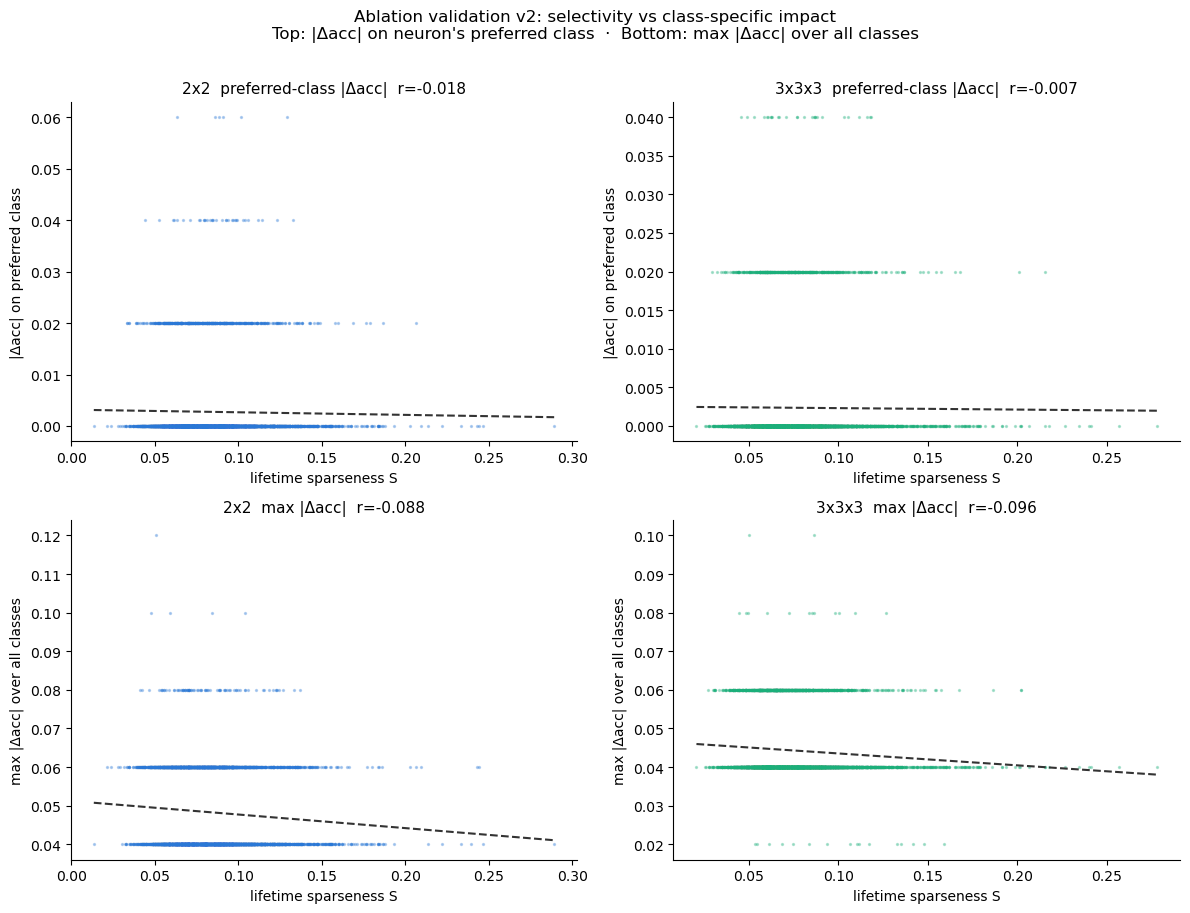

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for col, (label, d) in enumerate(data.items()):
    sel        = d['sel']           # (N_E,)
    abl_delta  = d['abl_delta']     # (N_E, 1000)
    pcm        = d['pcm']           # (N_E, 1000)

    # --- variant 1: Δacc on neuron's preferred class (argmax mean activation) ---
    pref_class   = pcm.argmax(axis=1)                              # (N_E,)
    pref_delta   = abl_delta[np.arange(N_E), pref_class]          # (N_E,) signed Δacc
    pref_abs     = np.abs(pref_delta)                              # (N_E,)

    ax = axes[0, col]
    ax.scatter(sel, pref_abs, s=2, alpha=0.3, color=COLORS[label], rasterized=True)
    z = np.polyfit(sel, pref_abs, 1)
    xr = np.linspace(sel.min(), sel.max(), 100)
    ax.plot(xr, np.poly1d(z)(xr), color='#333', lw=1.5, ls='--')
    r = np.corrcoef(sel, pref_abs)[0, 1]
    ax.set_xlabel('lifetime sparseness S', fontsize=10)
    ax.set_ylabel('|Δacc| on preferred class', fontsize=10)
    ax.set_title(f'{label}  preferred-class |Δacc|  r={r:.3f}', fontsize=11)
    ax.spines[['top', 'right']].set_visible(False)

    # --- variant 2: max |Δacc| across all classes ---
    max_abs = np.abs(abl_delta).max(axis=1)                        # (N_E,)

    ax = axes[1, col]
    ax.scatter(sel, max_abs, s=2, alpha=0.3, color=COLORS[label], rasterized=True)
    z = np.polyfit(sel, max_abs, 1)
    ax.plot(xr, np.poly1d(z)(xr), color='#333', lw=1.5, ls='--')
    r = np.corrcoef(sel, max_abs)[0, 1]
    ax.set_xlabel('lifetime sparseness S', fontsize=10)
    ax.set_ylabel('max |Δacc| over all classes', fontsize=10)
    ax.set_title(f'{label}  max |Δacc|  r={r:.3f}', fontsize=11)
    ax.spines[['top', 'right']].set_visible(False)

    print(f"\n{label}")
    print(f"  preferred-class |Δacc|: mean={pref_abs.mean():.4f}  r(sel,impact)={np.corrcoef(sel,pref_abs)[0,1]:.3f}")
    print(f"  max |Δacc|:             mean={max_abs.mean():.4f}  r(sel,impact)={np.corrcoef(sel,max_abs)[0,1]:.3f}")

plt.suptitle('Ablation validation v2: selectivity vs class-specific impact\n'
             'Top: |Δacc| on neuron\'s preferred class  ·  Bottom: max |Δacc| over all classes',
             fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig_selectivity_vs_ablation_v2.pdf', bbox_inches='tight')
plt.show()

2x2  mean signed Δacc=0.00002  r(S, mean_signed_Δacc)=-0.012
  44.0% of neurons hurt accuracy on average when ablated
3x3x3  mean signed Δacc=-0.00002  r(S, mean_signed_Δacc)=-0.020
  55.6% of neurons hurt accuracy on average when ablated


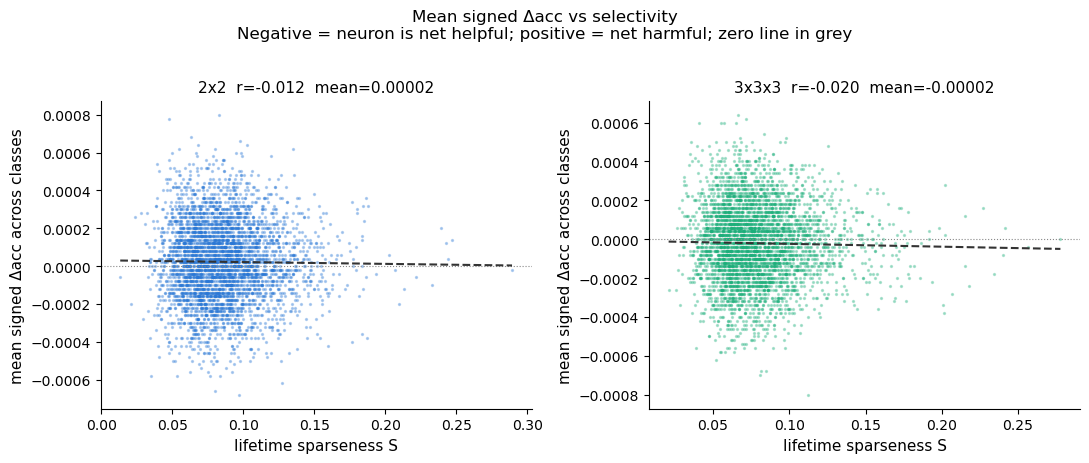

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for ax, (label, d) in zip(axes, data.items()):
    sel       = d['sel']                        # (N_E,)
    mean_signed = d['abl_delta'].mean(axis=1)   # (N_E,) — mean signed Δacc across all 1000 classes

    ax.scatter(sel, mean_signed, s=2, alpha=0.3, color=COLORS[label], rasterized=True)
    ax.axhline(0, color='#888', lw=0.8, ls=':')

    z = np.polyfit(sel, mean_signed, 1)
    xr = np.linspace(sel.min(), sel.max(), 100)
    ax.plot(xr, np.poly1d(z)(xr), color='#333', lw=1.5, ls='--')
    r = np.corrcoef(sel, mean_signed)[0, 1]

    mean_val = mean_signed.mean()
    ax.set_xlabel('lifetime sparseness S', fontsize=11)
    ax.set_ylabel('mean signed Δacc across classes', fontsize=11)
    ax.set_title(f'{label}  r={r:.3f}  mean={mean_val:.5f}', fontsize=11)
    ax.spines[['top', 'right']].set_visible(False)

    print(f"{label}  mean signed Δacc={mean_val:.5f}  r(S, mean_signed_Δacc)={r:.3f}")
    frac_neg = (mean_signed < 0).mean()
    print(f"  {frac_neg*100:.1f}% of neurons hurt accuracy on average when ablated")

plt.suptitle('Mean signed Δacc vs selectivity\n'
             'Negative = neuron is net helpful; positive = net harmful; zero line in grey',
             fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig_mean_signed_delta_vs_sel.pdf', bbox_inches='tight')
plt.show()

## Figure 5 — Parent (AlexNet) vs distilled (EINet) per-class accuracy

Each dot = one ImageNet class. X = AlexNet's accuracy on that class, Y = EINet's accuracy on that class.
- Points on the diagonal: EINet tracks AlexNet perfectly
- Points below the line: classes EINet struggles with more than AlexNet
- Points above the line: classes EINet surprisingly does better on

In [ ]:
import torch
import torchvision.models as tvm
from torch.utils.data import DataLoader
import sys
sys.path.insert(0, '/n/home13/adithyavm/dendritic-modeling/src')
from dendritic_modeling.datasets.standard_datasets import load_imagenet_as_datasets

IMAGENET_PATH = '/n/holylfs06/LABS/kempner_shared/Everyone/testbed/vision/imagenet_1k'
device = 'cuda' if torch.cuda.is_available() else 'cpu'

alexnet = tvm.alexnet(weights=tvm.AlexNet_Weights.IMAGENET1K_V1).to(device).eval()

_, _, val_ds = load_imagenet_as_datasets(
    train_valid_split=0.8, flatten=False, normalize=True,
    task_data_path=IMAGENET_PATH,
)
val_loader = DataLoader(val_ds, batch_size=256, shuffle=False, num_workers=2, pin_memory=True)

alexnet_preds, all_labels = [], []
with torch.no_grad():
    for imgs, lbls in val_loader:
        alexnet_preds.append(alexnet(imgs.to(device)).argmax(1).cpu())
        all_labels.append(lbls)

alexnet_preds = torch.cat(alexnet_preds).numpy()
labels = torch.cat(all_labels).numpy()

class_total   = np.bincount(labels, minlength=N_CLASSES).astype(np.float32)
class_correct = np.zeros(N_CLASSES, dtype=np.float32)
np.add.at(class_correct, labels, (alexnet_preds == labels).astype(np.float32))
alexnet_class_acc = np.where(class_total > 0, class_correct / class_total, 0.0)

print(f"AlexNet overall top-1: {alexnet_class_acc.mean()*100:.2f}%")


2x2  overall AlexNet=52.6%  EINet=51.5%
  5 classes EINet hurts most: ['Norfolk terrier', 'butcher shop', 'Appenzeller', 'miniature schnauzer', 'beagle']
  5 classes EINet does better: ['desktop computer', 'speedboat', 'table lamp', 'grille', 'EntleBucher']

3x3x3  overall AlexNet=52.6%  EINet=51.6%
  5 classes EINet hurts most: ['aircraft carrier', 'shoji', 'printer', 'butcher shop', 'tray']
  5 classes EINet does better: ['soft-coated wheaten terrier', 'mailbag', 'bolete', 'scabbard', 'cucumber']


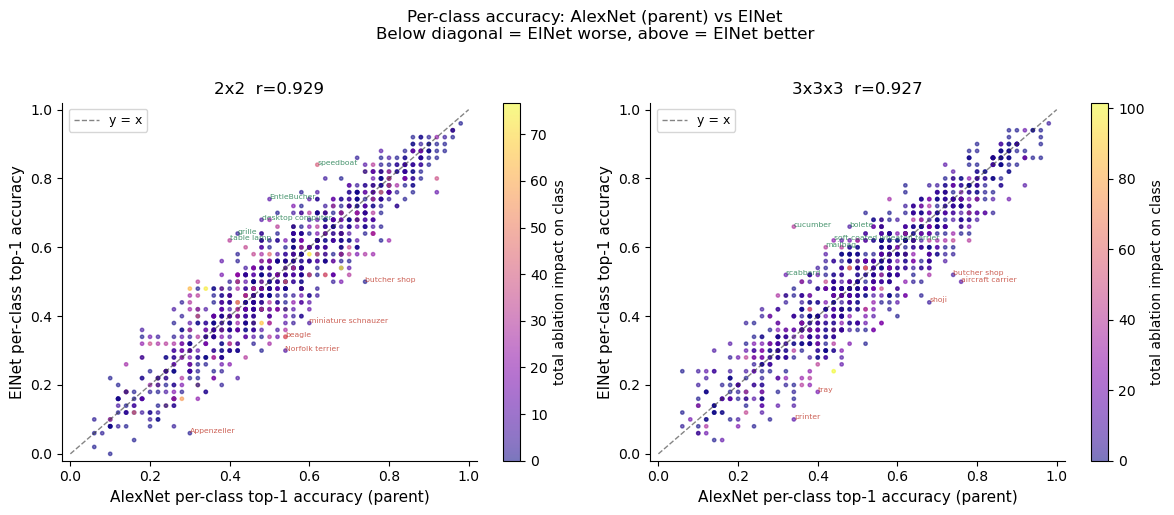

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (label, d) in zip(axes, data.items()):
    einet_acc = d['base_acc']   # (1000,) per-class accuracy for EINet

    # Color by ablation impact: how important is this class's neurons?
    total_impact = np.abs(d['abl_delta']).sum(axis=0)   # (1000,) sum over neurons per class

    sc = ax.scatter(alexnet_class_acc, einet_acc,
                    c=total_impact, cmap='plasma',
                    s=6, alpha=0.55, rasterized=True)
    plt.colorbar(sc, ax=ax, label='total ablation impact on class')

    # y=x diagonal
    lim = [0, 1]
    ax.plot(lim, lim, color='#333', lw=1, ls='--', alpha=0.6, label='y = x')

    # Correlation
    r = np.corrcoef(alexnet_class_acc, einet_acc)[0, 1]
    ax.set_xlabel('AlexNet per-class top-1 accuracy (parent)', fontsize=11)
    ax.set_ylabel('EINet per-class top-1 accuracy', fontsize=11)
    ax.set_title(f'{label}  r={r:.3f}', fontsize=12)
    ax.set_xlim(-0.02, 1.02); ax.set_ylim(-0.02, 1.02)
    ax.legend(fontsize=9)
    ax.spines[['top', 'right']].set_visible(False)

    # Annotate the biggest deviations (most hurt by EINet)
    delta = einet_acc - alexnet_class_acc
    worst5 = np.argsort(delta)[:5]
    best5  = np.argsort(delta)[-5:]
    for idx in worst5:
        ax.annotate(class_names[idx], (alexnet_class_acc[idx], einet_acc[idx]),
                    fontsize=5.5, color='#c0392b', alpha=0.8)
    for idx in best5:
        ax.annotate(class_names[idx], (alexnet_class_acc[idx], einet_acc[idx]),
                    fontsize=5.5, color='#1a7a4a', alpha=0.8)

    print(f"\n{label}  overall AlexNet={alexnet_class_acc.mean()*100:.1f}%  EINet={einet_acc.mean()*100:.1f}%")
    print(f"  5 classes EINet hurts most: {[class_names[i] for i in worst5]}")
    print(f"  5 classes EINet does better: {[class_names[i] for i in best5]}")

plt.suptitle('Per-class accuracy: AlexNet (parent) vs EINet\n'
             'Below diagonal = EINet worse, above = EINet better', fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig5_parent_vs_einet_class_acc.pdf', bbox_inches='tight')
plt.show()